In [24]:
#%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu132
from torch.utils.data import DataLoader
from torchvision import datasets 
from torchvision import transforms

# **Task 1: Getting The CIFAR Dataset**

In [25]:
train_dataset = torchvision.datasets.CIFAR10(
    root="../dataset",
    train= True,
    download=True,
    transform=torchvision.transforms.ToTensor()
)

test_dataset = torchvision.datasets.CIFAR10(
    root="../dataset",
    train= False,
    download=True,
    transform=torchvision.transforms.ToTensor()
)

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size= 128,
    shuffle= True,
    num_workers= 0
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0,
)
print(f"Dataloaded successfully!\nTrain length: {len(train_dataset)}\n Test Length: {len(test_dataset)}\n Classes: {train_dataset.classes}")

Dataloaded successfully!
Train length: 50000
 Test Length: 10000
 Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


# **Task 2: Define The Network**

In [ ]:
import torch.nn as nn

class CNN (nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3,32,3, padding=1),   #32x32x3
            nn.ReLU(),
            nn.MaxPool2d(2),                #16x16x32
            nn.Conv2d(32,64,3,padding=1),   #16x16x64
            nn.ReLU(),
            nn.MaxPool2d(2),                #8x8x64
            nn.Conv2d(64,128,3,padding=1),  #8x8x128
            nn.ReLU(),
            nn.MaxPool2d(2)                 #4x4x128
        )
        self.classifier  = nn.Sequential(
            nn.Flatten(),
            nn.Linear(4*4*128, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256,10)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

# **Task 3: Loading Data**

Images Tensor size: torch.Size([128, 3, 32, 32])
Label Tensor size: torch.Size([128])


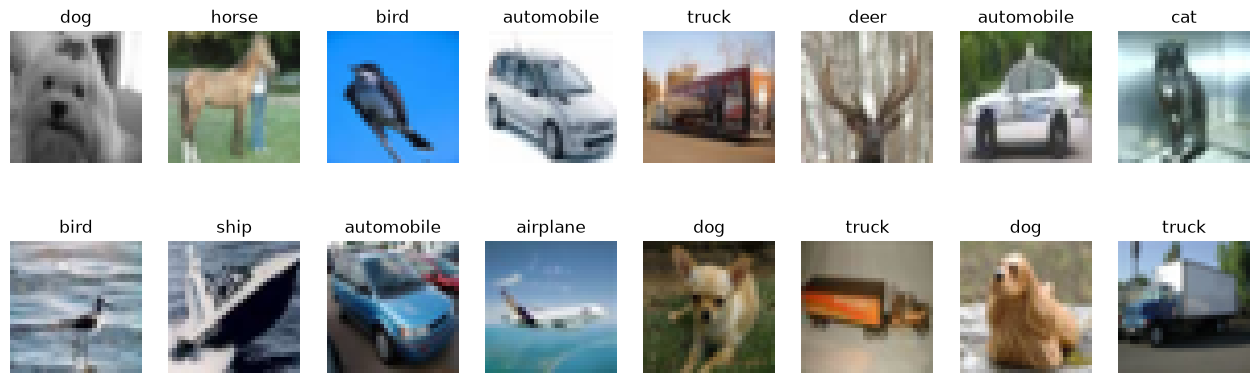

In [27]:
images, label = next(iter(train_loader)) 
print(f"Images Tensor size: {images.shape}")    # [Batch size, channel,width,height]
print(f"Label Tensor size: {label.shape}")      # [Batch size]

#!pip install matplotlib
import matplotlib.pyplot as plt

classes = train_dataset.classes
fig, axes = plt.subplots(2, 8, figsize=(16, 5))
for img, label, ax in zip(images, label, axes.flat):
    ax.imshow(img.permute(1, 2, 0))  
    ax.set_title(classes[label])
    ax.axis("off")
plt.show()


# **Task 4: Dataset Augmentation**

In [ ]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomResizedCrop(32, scale=(0.7, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])